# Cre-lox recombination: motifs, sites and strand exchange

Cre recombinase finds two loxP sites and swaps the DNA strands across them. What comes out depends only on how the two sites sit relative to each other. This notebook builds that up in Gen's terms, starting with one pair of sites and ending with every product a cassette of several sites can make.

Four ideas appear in this order:

- A `Motif` is the definition of a site: the sequence an enzyme recognises and where it cuts inside it.
- A `Site` is one place in a graph where a motif matched. `motif.apply(hit)` turns a search hit into a site, which knows the breakpoints where its strands are cut.
- A strand exchange takes two breakpoints and swaps what follows them. `SequenceGraph.exchange` does it for breakpoints, and `SequenceGraph.recombine` does it for two sites. Underneath both, `SequenceGraph.connect` adds a single edge, and an exchange is two of them.
- `crelox()` combines every compatible pair of sites with each other and repeats on the products. We write it ourselves in the middle of the notebook; it is a short loop over the other three ideas.

The short P1 and P2 blocks are schematic labels, not functional designs.

In [1]:
import tempfile

import gen
from IPython.display import display

repository = gen.Repository(tempfile.mkdtemp(prefix="cre-principles-"))

COMPLEMENT = str.maketrans("ACGT", "TGCA")


def reverse_complement(sequence):
    return sequence.translate(COMPLEMENT)[::-1]


# LoxP is two 13 bp arms around an 8 bp spacer. The spacer is not a palindrome, so the site
# has a direction. Cre really cuts the top strand after base 13 and the bottom strand after
# base 21, leaving the spacer as an 8 base overhang. Strand exchange between staggered sites is
# not modelled yet, so for now each site gets one blunt cut at base 17, the middle of the spacer.
LOXP = "ATAACTTCGTATAATGTATGCTATACGAAGTTAT"
LOXP_REVERSED = reverse_complement(LOXP)
CUT = 17

# Naming the arms and the spacer lets a site be read part by part. The spacer is what decides
# which sites can react with each other and which way a site faces.
LOXP_PARTS = {"left": (0, 13), "spacer": (13, 21), "right": (21, 34)}
loxp = gen.Motif(LOXP, CUT, name="loxP", parts=LOXP_PARTS)
assert not loxp.palindromic

# The DNA around and between sites: two flanks and two short blocks.
UPSTREAM = "GCGGTTAC"
DOWNSTREAM = "TTCGACGA"
P1 = "TTGACACCTATA"
P2 = "CGGATAGCTTAC"

Two small helpers keep the cells below short. `show` plots a graph, and `layouts` reads the order and orientation of P1 and P2 along every linear molecule in a graph, so each example can check what it claims.

In [2]:
def show(graph, **options):
    display(graph.plot(interactive=False, detail="labels", show_history=True, **options))


def layouts(sequence_graph):
    """Read the order and orientation of P1 and P2 from each linear sequence, as a check."""
    blocks = (("P1", P1), ("P2", P2))
    names = set()
    for sequence in sequence_graph.all_sequences():
        text = str(sequence)
        found = []
        for label, block in blocks:
            for spelling, oriented_label in ((block, label), (reverse_complement(block), "-" + label)):
                position = text.find(spelling)
                if position >= 0:
                    found.append((position, oriented_label))
        names.add(tuple(label for _, label in sorted(found)))
    return sorted(names)

## One pair of sites, four orientations

The smallest useful cassette is `upstream – loxP – P1 – loxP – downstream`. Two sites split the chromosome into three parts. LoxP has a direction, so each site faces one of two ways: `+` reads as the motif spells it and `−` is its reverse complement. Two sites with two directions each give four cassettes.

Cre treats every pair the same way, by crossing the strands over inside the two spacers. Only the outcome changes, and the orientation alone decides it: sites facing the same way (direct repeats) cut out what lies between them as a circle, and sites facing opposite ways (inverted repeats) turn it around.

### Both sites forward (++): excision

The first cell shows every step. Importing the sequence gives a graph. A `search` for the motif's recognition site returns one locus per match, and we know this cassette has exactly two, so we can unpack them as `[left_hit, right_hit]`. `loxp.apply(hit)` turns each into a `Site` with its cut positions. Annotating the sites and P1 only gives the plot labels. `recombine` exchanges the strands across the two sites, and `split=True` gives each resulting molecule a graph of its own.

The plots show the starting cassette, then the shortened chromosome, then the circle that carries P1.

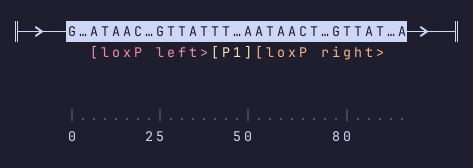

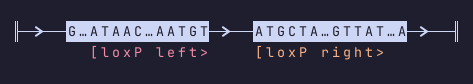

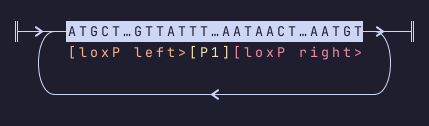

In [3]:
sequence = UPSTREAM + LOXP + P1 + LOXP + DOWNSTREAM
sg = repository.import_sequence(sequence, name="lox_forward_forward", sample="lox_forward_forward")

[left_hit, right_hit] = sg.search(loxp.recognition_site)
left, right = loxp.apply(left_hit), loxp.apply(right_hit)
sg.add_annotation(left.locus, "loxP left", track="sites")
sg.add_annotation(right.locus, "loxP right", track="sites")
sg.add_annotation(sg.search(P1, sequence_kind="exact")[0], "P1", track="blocks")
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert sorted(layout for product in products for layout in layouts(product)) == [(), ("P1",)]

Each product keeps one loxP site: one stays in the chromosome where P1 used to be, and one closes the circle. That detail matters later, because a surviving site can react again.

From here on a helper does the import, the search and the annotation. It returns the sites ordered along the molecule, so a two-site cassette unpacks as `[left, right]` and a three-site one as `[left, middle, right]`. A site's label shows its direction when the motif has one.

In [4]:
def cassette(name, *parts, motif=loxp, **search_options):
    """Import the parts as one molecule, find its sites left to right, and label sites and blocks."""
    sg = repository.import_sequence("".join(parts), name=name, sample=name)
    sites = [motif.apply(hit) for hit in sg.search(motif.recognition_site, **search_options)]
    sites.sort(key=lambda site: min(site.locus.start().offset, site.locus.end().offset))
    names = {1: ["site"], 2: ["left", "right"], 3: ["left", "middle", "right"]}[len(sites)]
    for name, site in zip(names, sites):
        direction = "" if motif.palindromic else f" {site.locus[0].strand}"
        sg.add_annotation(site.locus, f"{motif.name} {name}{direction}", track="sites")
    for label, block in (("P1", P1), ("P2", P2)):
        if block in parts:
            sg.add_annotation(sg.search(block, sequence_kind="exact")[0], label, track="blocks")
    return sg, sites


def outcome(products):
    return sorted(layout for product in products for layout in layouts(product))

### Both sites reverse (−−): excision again

Flipping both sites changes nothing about their relation to each other. They still face the same way, so P1 is still excised.

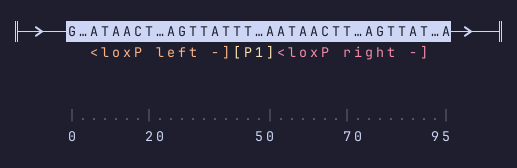

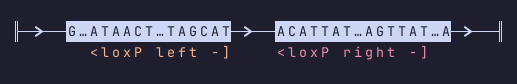

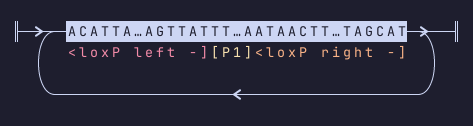

In [5]:
sg, [left, right] = cassette("lox_reverse_reverse", UPSTREAM, LOXP_REVERSED, P1, LOXP_REVERSED, DOWNSTREAM)
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [(), ("P1",)]

### Forward then reverse (+−): inversion

Now the sites face each other. The strand exchange joins each flank to the far end of the other site, so P1 is read backwards between the same flanks and nothing leaves the chromosome.

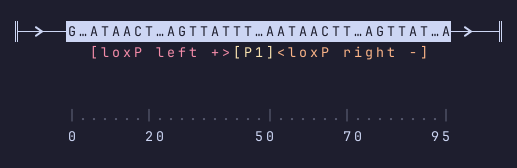

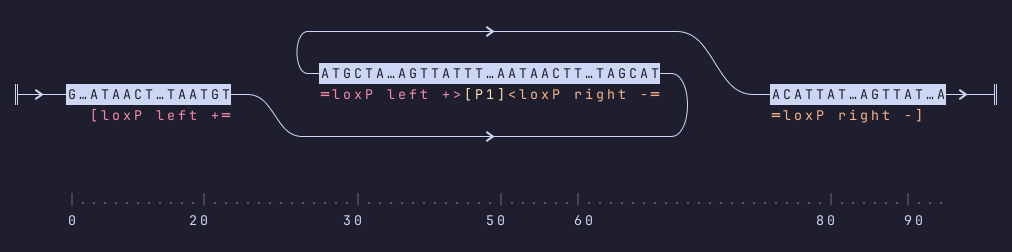

In [6]:
sg, [left, right] = cassette("lox_forward_reverse", UPSTREAM, LOXP, P1, LOXP_REVERSED, DOWNSTREAM)
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [("-P1",)]

### Reverse then forward (−+): inversion again

The mirror image of the last cassette, and the same result.

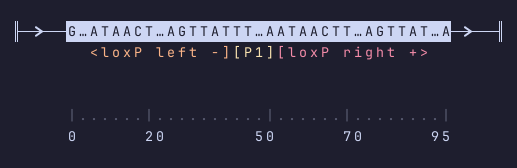

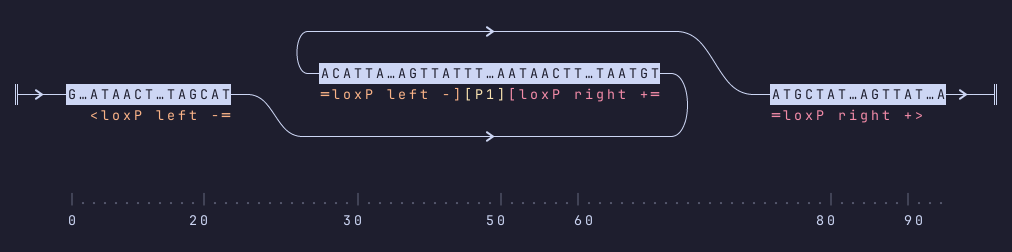

In [7]:
sg, [left, right] = cassette("lox_reverse_forward", UPSTREAM, LOXP_REVERSED, P1, LOXP, DOWNSTREAM)
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [("-P1",)]

### What the orientation decides

| Cassette | Relation | Product |
|---|---|---|
| `++` and `−−` | direct repeats | P1 leaves as a circle, the chromosome is shorter |
| `+−` and `−+` | inverted repeats | P1 is reversed in place |

Because loxP has a direction, a pair of sites can only line up one way. The arrangement you build is the reaction you get, and the rest of the story follows from that. An inversion also leaves two sites facing each other, so it can be undone, while an excision leaves one site on the chromosome and one on the circle.

### Reading the orientation from the sites

The motif names the two arms and the spacer (`parts`), so a site can be read part by part with `site.part("spacer")`. The spacer matters most, because it decides both which sites can react and which way each one faces. Two sites whose spacers differ cannot exchange strands, and two that match are direct repeats when their spacers read the same way and inverted repeats when they read opposite ways. The cell below reads that off the sites as they are found, for each of the four cassettes.

In [8]:
def relation(first, second):
    """How two sites sit relative to each other, read from their spacers."""
    first_spacer, second_spacer = first.part("spacer"), second.part("spacer")
    if first_spacer.sequence != second_spacer.sequence:
        return "incompatible"
    return "direct" if first_spacer.direction == second_spacer.direction else "inverted"


for name, left_site, right_site, expected in (
    ("++", LOXP, LOXP, "direct"),
    ("−−", LOXP_REVERSED, LOXP_REVERSED, "direct"),
    ("+−", LOXP, LOXP_REVERSED, "inverted"),
    ("−+", LOXP_REVERSED, LOXP, "inverted"),
):
    _, [left, right] = cassette(f"lox_relation_{name}", UPSTREAM, left_site, P1, right_site, DOWNSTREAM)
    assert relation(left, right) == expected
    print(name, relation(left, right))

++ direct
−− direct
+− inverted
−+ inverted


## Inside crelox()

A real population does not stop after one event. Cre acts on whichever sites are available, and the product of one reaction can contain sites that react again. `crelox()` captures that: it combines every compatible pair of sites with each other, and keeps going until no new pair appears. Writing it takes three steps, which are the same three steps used above, so we take them one at a time.

### Finding the sites

A `Motif` is the definition, and a search turns it into places. `sg.search(motif.recognition_site)` returns a locus for each match, and `motif.apply(locus)` returns the `Site` the motif defines there. Cuts are counted along the motif, so a site on the reverse strand is flipped by `apply` and then reads exactly like one on the forward strand.

That works in every cassette so far. The catch is that `sg.search` looks on both strands at once, and once a graph contains an inversion junction, a hit on the reverse strand can come back spelling the wrong bases. `apply` then raises, because the locus is not an instance of the motif. A closure meets such graphs all the time, so `find_sites` avoids the double-stranded search:

1. Search the forward strand for the recognition site. Every hit is a site facing forward.
2. Search the forward strand for the reverse complement of the recognition site. Every hit is a site sitting on the reverse strand, so reverse it with `hit.reverse_complement()` to make it read along the motif.

A palindromic motif is its own reverse complement, so a second search would find the same sites again and is skipped. `gen.recombination_closure` uses this same workaround.

In [9]:
def find_sites(sequence_graph, motif):
    """Every site of `motif` in the graph, each read along the motif."""
    pattern = motif.recognition_site
    hits = sequence_graph.search(pattern, sequence_kind="exact")
    if not motif.palindromic:
        opposite = sequence_graph.search(reverse_complement(pattern), sequence_kind="exact")
        hits += [hit.reverse_complement() for hit in opposite]
    return [motif.apply(hit) for hit in hits]


sg, _ = cassette("lox_three_forward", UPSTREAM, LOXP, P1, LOXP, P2, LOXP, DOWNSTREAM)
sites = find_sites(sg, loxp)
print(len(sites), "sites")

3 sites


### Pairing the sites

`gen.site_pairs(sites)` lists every pair of distinct sites whose cuts leave ends that can anneal. Three sites give three pairs. A palindromic site has no direction, so a pair of those is offered in both alignments; we come back to that at the end.

In [10]:
pairs = list(gen.site_pairs(sites))
print(len(pairs), "pairs")

3 pairs


### Exchanging strands

`sg.recombine(left, right)` looks like one step, and it is two. This function does what it does:

- Check that the ends the exchange leaves can anneal. Blunt sites always can. Staggered sites need the same overhang, base for base.
- Take the top-strand cut of each site, `site.top_break`, and exchange the strands across those two cuts with `sg.exchange`.

In [11]:
def recombine_by_hand(sequence_graph, first, second, **options):
    first.check_overhang_matches(second)
    return sequence_graph.exchange(first.top_break, second.top_break, **options)

`top_break` is a `Breakpoint(A, B)`: a cut between two neighbouring nucleotides, read upstream to downstream on one strand. Real loxP is cut at the two ends of the spacer, one end on each strand. Here it is modelled as the single blunt cut in the middle of the spacer, which gives the same product sequences because the two spacers match, though not which parent the overhang bases come from. With the left site cut at `A|B` and the right at `C|D`, `sg.exchange((A, B), (C, D))` joins `A` to `D` and `C` to `B`. Those are the two junctions of a recombinase crossing over, and no others are made.

One level further down, each junction is a single edge, which is what `sg.connect(after=A, before=D)` adds. So the same excision can be written three ways, and the cell below checks that they agree.

In [12]:
def excise(method):
    sg, [left, right] = cassette(f"lox_three_ways_{method}", UPSTREAM, LOXP, P1, LOXP, DOWNSTREAM)
    if method == "connect":
        (a, b), (c, d) = left.top_break, right.top_break
        sg.connect(after=a, before=d)
        sg.connect(after=c, before=b)
    elif method == "exchange":
        sg.exchange(left.top_break, right.top_break)
    elif method == "recombine_by_hand":
        recombine_by_hand(sg, left, right)
    else:
        sg.recombine(left, right)
    return sorted(str(sequence) for sequence in sg.all_sequences())


results = [excise(method) for method in ("connect", "exchange", "recombine_by_hand", "recombine")]
assert all(result == results[0] for result in results)
results[0]

['GCGGTTACATAACTTCGTATAATGTATGCTATACGAAGTTATTTCGACGA']

`recombine` does not decide whether a particular enzyme permits a pair. LoxP pairs with LoxP, and that rule belongs to the caller. A serine integrase would use the same `Site(locus, top, bottom)` with its staggered cuts, and a rule that only allows `attP` with `attB`. The strand exchange underneath is the same.

### Repeating until nothing is new

After an exchange the graph can contain new sites, for example the loxP left on the chromosome of an excision. So the loop searches again and only stops once every pair has been tried. Two details are worth knowing:

- `stack=True` keeps the original continuity as an alternative instead of deleting it. Every product then lives in one graph as another path through it, which is what lets the next search see all of them.
- A stacked graph can hold alternatives that never share a molecule, such as the chromosome before and after an excision. A pair taken from two such alternatives is not joined in the graph, `exchange` raises "not joined", and the loop skips it.

Here is the whole function.

In [13]:
def physical(site):
    """The stretch of DNA a site covers, the same from either strand."""
    return frozenset((site.locus, site.locus.reverse_complement()))


def crelox(sequence_graph, motif):
    """Combine every compatible pair of sites, then search the products and repeat."""
    tried = set()
    while True:
        sites = find_sites(sequence_graph, motif)
        pending = []
        for first, second in gen.site_pairs(sites):
            pair = frozenset((physical(first), physical(second)))
            pending.append((pair, first, second))
        pending = [item for item in pending if item[0] not in tried]
        if not pending:
            return
        tried.update(pair for pair, _, _ in pending)
        for _, first, second in pending:
            try:
                sequence_graph.exchange(first.top_break, second.top_break, stack=True)
            except ValueError as error:
                if "not joined" not in str(error):
                    raise

Gen ships the same loop as `gen.recombination_closure(sequence_graph, motif)`, which also accepts a `compatible(first, second)` rule for cases like `attP` with `attB`. The next cell checks that the function above finds the same molecules.

In [14]:
sg_own, _ = cassette("lox_check_own", UPSTREAM, LOXP, P1, LOXP, P2, LOXP_REVERSED, DOWNSTREAM)
sg_library, _ = cassette("lox_check_library", UPSTREAM, LOXP, P1, LOXP, P2, LOXP_REVERSED, DOWNSTREAM)
crelox(sg_own, loxp)
gen.recombination_closure(sg_library, loxp)
assert layouts(sg_own) == layouts(sg_library)
len(layouts(sg_own))

7

### crelox() on one pair

With a single pair there is a single reaction, so the closure is the starting molecule plus its one product. The first plot is the intact cassette and the second the stacked graph of both linear paths. Direct repeats give P1 present or absent, and inverted repeats give P1 forward or reversed.

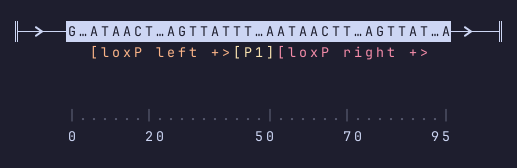

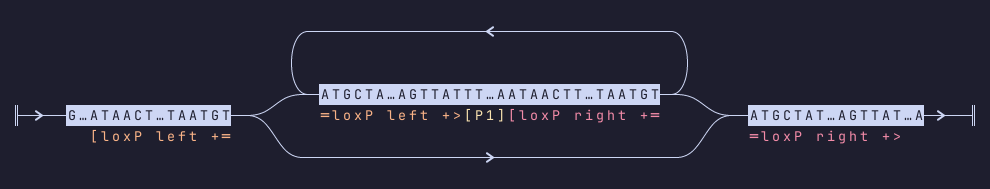

In [15]:
sg, _ = cassette("lox_pair_direct", UPSTREAM, LOXP, P1, LOXP, DOWNSTREAM)
show(sg)
crelox(sg, loxp)
show(sg, rows=80, cols=300, align_path=False)
assert layouts(sg) == [(), ("P1",)]

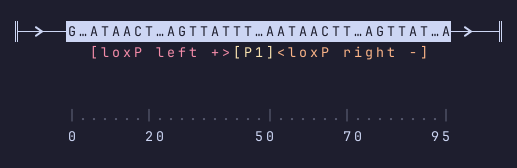

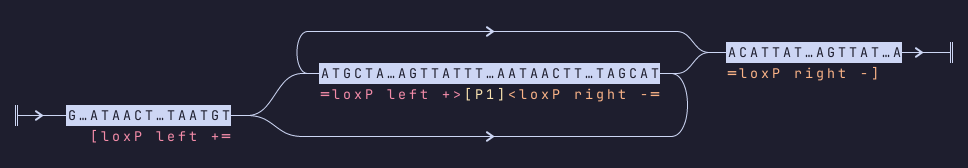

In [16]:
sg, _ = cassette("lox_pair_inverted", UPSTREAM, LOXP, P1, LOXP_REVERSED, DOWNSTREAM)
show(sg)
crelox(sg, loxp)
show(sg, rows=80, cols=300, align_path=False)
assert layouts(sg) == [("-P1",), ("P1",)]

The other two orientations behave the same way: `−−` matches `++` and `−+` matches `+−`. Whichever of the four you start from, one pair of directional sites gives exactly two linear layouts.

In [17]:
two_site_layouts = {}
for name, left, right in (
    ("++", LOXP, LOXP),
    ("−−", LOXP_REVERSED, LOXP_REVERSED),
    ("+−", LOXP, LOXP_REVERSED),
    ("−+", LOXP_REVERSED, LOXP),
):
    sg, _ = cassette(f"lox_pair_{name}", UPSTREAM, left, P1, right, DOWNSTREAM)
    crelox(sg, loxp)
    two_site_layouts[name] = layouts(sg)
    assert len(two_site_layouts[name]) == 2
two_site_layouts

{'++': [(), ('P1',)],
 '−−': [(), ('P1',)],
 '+−': [('-P1',), ('P1',)],
 '−+': [('-P1',), ('P1',)]}

## Three sites

Adding a third site makes three parts out of two blocks, and gives `crelox()` three pairs to start from. Every product of those can contain further sites, so the closure grows. We compare three forward sites (`+++`) with a reversed final site (`++−`).

### Three forward sites: excision

The outer pair, `left` and `right`, removes both blocks. The first plot is the intact cassette, then the shortened chromosome, then the circle carrying P1 and P2.

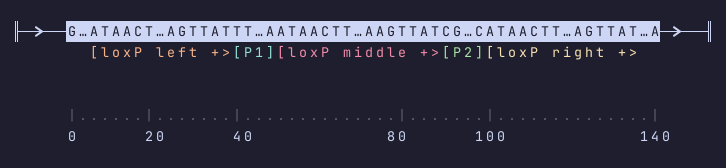

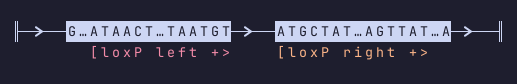

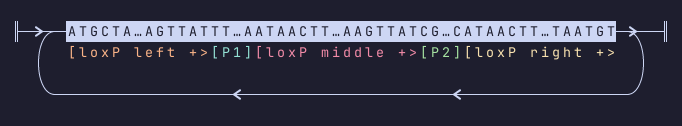

In [18]:
sg, [left, middle, right] = cassette("lox_three_direct", UPSTREAM, LOXP, P1, LOXP, P2, LOXP, DOWNSTREAM)
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [(), ("P1", "P2")]

### Three forward sites: closure

The other two pairs each remove one block, and the junction left by any excision is still a loxP site. The closure keeps five linear layouts: both blocks, only P1, only P2, neither, and the two blocks in the original order.

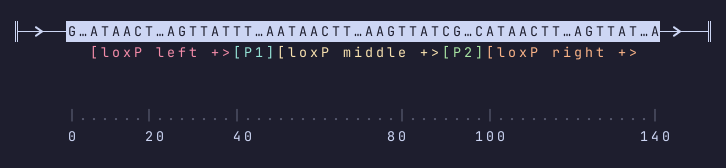

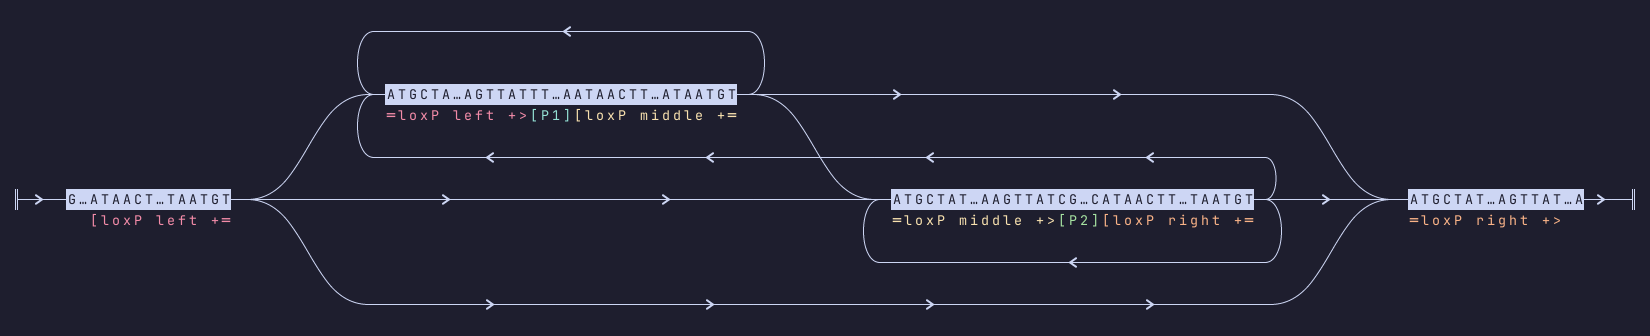

In [19]:
sg, _ = cassette("lox_three_closure_direct", UPSTREAM, LOXP, P1, LOXP, P2, LOXP, DOWNSTREAM)
show(sg)
crelox(sg, loxp)
show(sg, rows=80, cols=300, align_path=False)
three_forward_layouts = layouts(sg)
assert len(three_forward_layouts) == 5

### One reversed site: inversion

With the last site reversed, the outer pair now inverts the segment between them, so the blocks read reversed P2 followed by reversed P1.

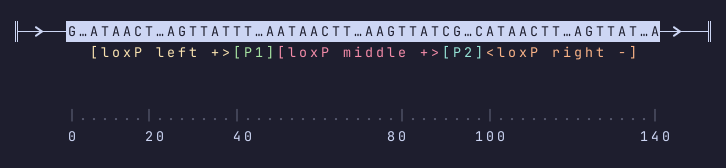

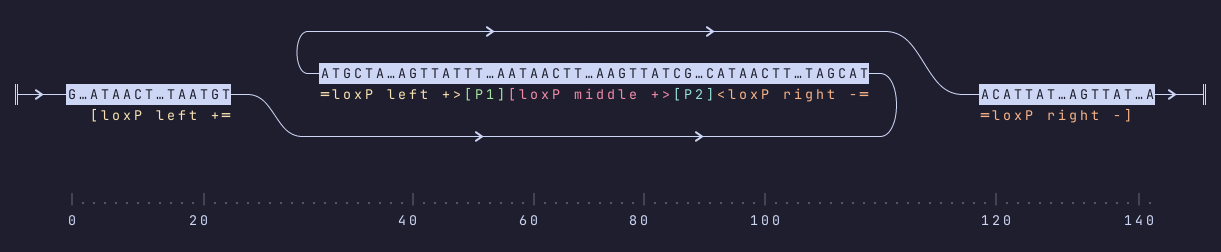

In [20]:
sg, [left, middle, right] = cassette("lox_three_mixed", UPSTREAM, LOXP, P1, LOXP, P2, LOXP_REVERSED, DOWNSTREAM)
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [("-P2", "-P1")]

### One reversed site: closure

Now some pairs excise and others invert, and an inversion changes which sites face which. The closure holds seven linear layouts, including the single-block and reversed-block products.

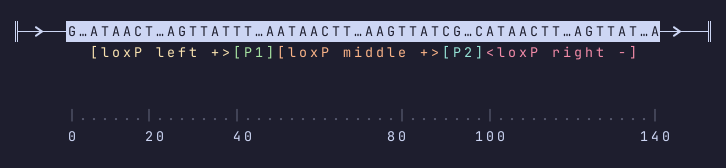

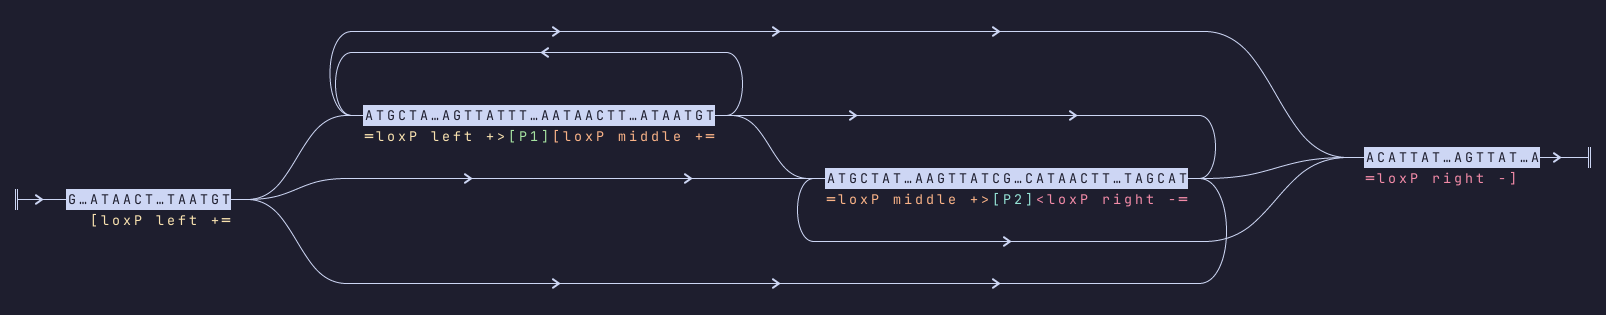

In [21]:
sg, _ = cassette("lox_three_closure_mixed", UPSTREAM, LOXP, P1, LOXP, P2, LOXP_REVERSED, DOWNSTREAM)
show(sg)
crelox(sg, loxp)
show(sg, rows=80, cols=300, align_path=False)
three_mixed_layouts = layouts(sg)
assert len(three_mixed_layouts) == 7

## Sites without a direction: LoxPsym

The loxP variant most people meet first is the directional one used above. A variant with a palindromic spacer, here called LoxPsym, reads the same on both strands. It has no direction, so two LoxPsym sites do not fix how they line up. The same cassette can excise or invert depending on which alignment the enzyme takes, and `gen.site_pairs` offers both. Compare the four orientations of directional sites, where each cassette had one reaction, with one cassette that has two.

In [22]:
LOXPSYM = "ATAACTTCGTATATTATATAATATACGAAGTTAT"
assert reverse_complement(LOXPSYM) == LOXPSYM

loxpsym = gen.Motif(LOXPSYM, CUT, name="LoxPsym", parts=LOXP_PARTS)
assert loxpsym.palindromic

sg, [left, right] = cassette("sym_pair", UPSTREAM, LOXPSYM, P1, LOXPSYM, DOWNSTREAM, motif=loxpsym, sequence_kind="exact")
print(len(list(gen.site_pairs([left, right]))), "alignments of one pair")

2 alignments of one pair


One pair of sites gives two alignments. Taking the right site as found is the direct alignment, and `right.reverse_complement()` says "align this one the other way round". The first plot is the intact cassette, then the excision products, then the inversion.

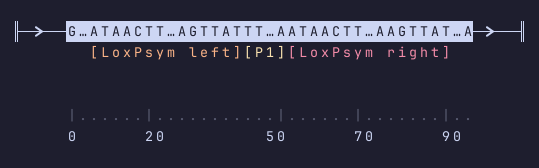

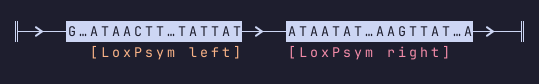

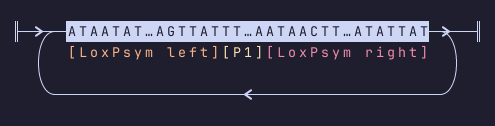

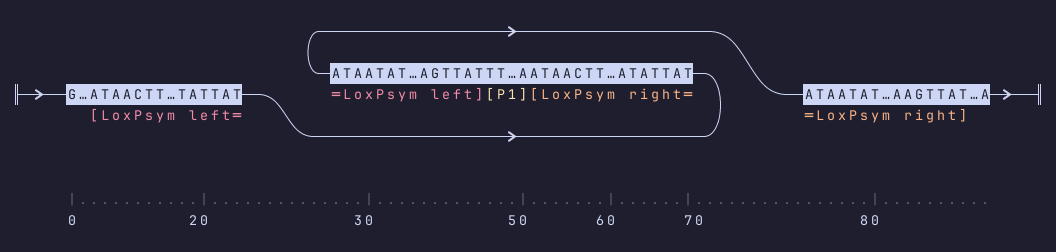

In [23]:
show(sg)

products = sg.recombine(left, right, split=True)
for product in products:
    show(product)
assert outcome(products) == [(), ("P1",)]

sg, [left, right] = cassette("sym_pair_inverted", UPSTREAM, LOXPSYM, P1, LOXPSYM, DOWNSTREAM, motif=loxpsym, sequence_kind="exact")
products = sg.recombine(left, right.reverse_complement(), split=True)
for product in products:
    show(product)
assert outcome(products) == [("-P1",)]

The closure of one LoxPsym pair holds P1 forward, P1 reversed, and P1 absent: three layouts, where any single directional pair gave two.

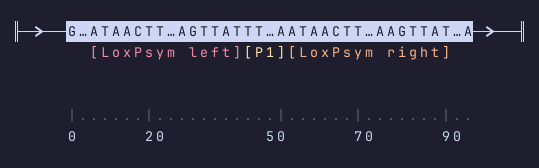

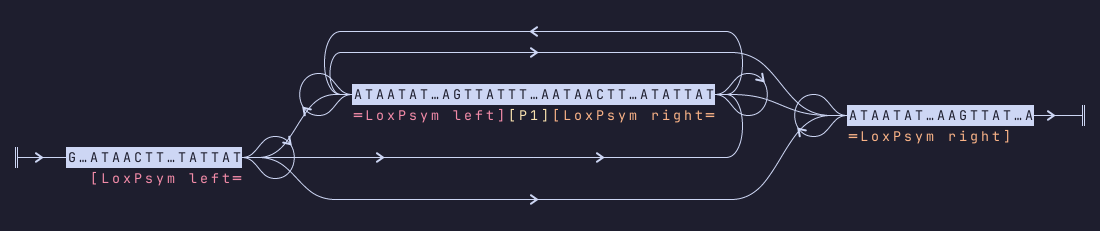

In [24]:
sg, _ = cassette("sym_pair_closure", UPSTREAM, LOXPSYM, P1, LOXPSYM, DOWNSTREAM, motif=loxpsym, sequence_kind="exact")
show(sg)
crelox(sg, loxpsym)
show(sg, rows=80, cols=300, align_path=False)
two_symmetric_layouts = layouts(sg)
assert set(two_symmetric_layouts) == {(), ("P1",), ("-P1",)}

Three LoxPsym sites show how fast this grows. Each of the three pairs has two alignments, and every product has sites that react again. The closure keeps 13 layouts: neither block, four with one oriented block, and eight with both blocks in either order and orientation. These are distinct simple paths, not reaction frequencies.

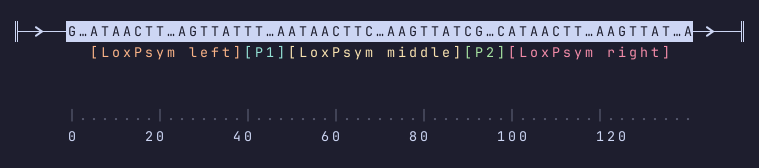

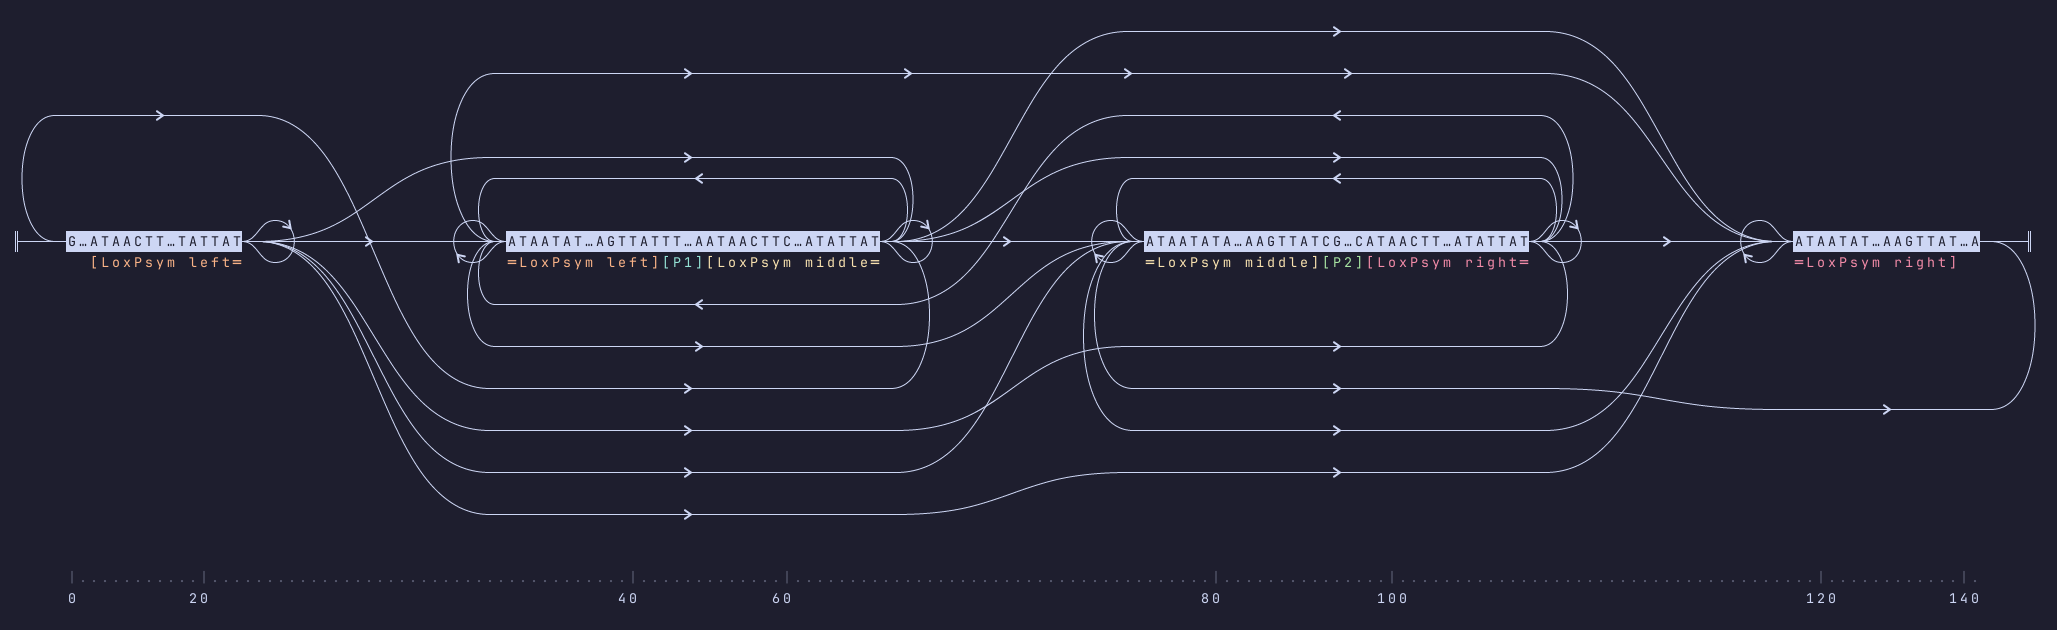

In [25]:
sg, _ = cassette("sym_three_closure", UPSTREAM, LOXPSYM, P1, LOXPSYM, P2, LOXPSYM, DOWNSTREAM, motif=loxpsym, sequence_kind="exact")
show(sg)
crelox(sg, loxpsym)
show(sg, rows=80, cols=300)
three_symmetric_layouts = layouts(sg)
assert len(three_symmetric_layouts) == 13

## Side by side

The same cassettes, counted by the number of distinct linear layouts the closure reaches.

In [26]:
rows = (
    ("two sites, directional loxP", len(two_site_layouts["++"])),
    ("two sites, LoxPsym", len(two_symmetric_layouts)),
    ("three sites, all forward", len(three_forward_layouts)),
    ("three sites, last one reversed", len(three_mixed_layouts)),
    ("three sites, LoxPsym", len(three_symmetric_layouts)),
)
for label, count in rows:
    print(f"{label:34s}{count:3d}")

two sites, directional loxP         2
two sites, LoxPsym                  3
three sites, all forward            5
three sites, last one reversed      7
three sites, LoxPsym               13


A directional site commits each pair to one reaction, so you can design a cassette to excise or to invert and expect that outcome. A site without direction leaves both open, and that is why LoxPsym cassettes drift toward so many more arrangements.

## Interpreting the closure graphs

The closure explores graph-site pairs; these are not cells or biochemical events in a culture. `len(graph.all_sequences())` counts distinct simple linear sequences that Gen enumerates; circles and walks revisiting a cycle lie outside that number. A stacked graph can also combine edges from different reactions, so its sequence count needs an independent reachability check before it is used as a genotype count.

`gembler_exchange.ipynb` searches newly formed sites to closure and reports **75,973** six-block linear layouts, matching its independent deletion/inversion layout enumeration. That agreement concerns layouts with at most one copy of each original block. It does not count circles, repeated walks, or every intermolecular duplication and translocation.